In [ ]:
# 整理后的R包加载与配置

# 基础分析包
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
# suppressMessages(library(Nebulosa))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))

# 多组学/转录因子包
suppressMessages(library(scMEGA))
suppressMessages(library(Pando))
suppressMessages(library(harmony))
suppressMessages(library(enrichR))

# motif 分析等
# suppressMessages(library(JASPAR2020))
suppressMessages(library(JASPAR2024))
suppressMessages(library(TFBSTools))
suppressMessages(library(chromVAR))
suppressMessages(library(motifmatchr))

# 可视化
suppressMessages(library(igraph))
suppressMessages(library(ggraph))

# 基因组分析
# suppressMessages(library(BSgenome.Hsapiens.UCSC.hg38))
suppressMessages(library(GenomicRanges))
suppressMessages(library(BSgenome))
suppressMessages(library(Rsamtools))  # FaFile
suppressMessages(library(ChIPseeker))
suppressMessages(library(GenomicFeatures))
suppressMessages(library(rtracklayer)) # 读写 BED/GFF
suppressMessages(library(txdbmaker))
suppressMessages(library(enrichR))
library(tidyr)
library(foreach)
library(doParallel)



# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_snRNA_snATAC/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_snRNA_snATAC/.venv")

# 资源设定
plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)

# 加载 genome 注释
load('/home/chaiqw/project/macaque_motor_new/macFas5_genomeInfo_signac.RData')
data("motifs");data('motif2tf')
library(pheatmap)
library(dplyr)




载入程序包：‘tidyr’


The following object is masked from ‘package:S4Vectors’:

    expand


The following object is masked from ‘package:igraph’:

    crossing


载入需要的程序包：iterators



In [ ]:
obj = readRDS('/home/chaiqw/project/betz_anal_new/coembed_5000feature-new05.rds')

sub_rna = subset(obj, tech == 'RNA')
sub_rna$ET_class <- ifelse(sub_rna$seurat_clusters == 2, "Betz Like cluster", "other L5_ET-neuron")
obj_1 = subset(obj, tech == 'ATAC')

obj_1$ET_class <- ifelse(obj_1$seurat_clusters == 2, "Betz Like cluster", "other L5_ET-neuron")

obj_sub = subset(obj_1, obj_1$seurat_clusters == 2)
obj_sub

peaks assay doesn't leave any cells, so it is removed

GeneActivity assay doesn't leave any cells, so it is removed



An object of class Seurat 
730339 features across 325 samples within 3 assays 
Active assay: RNA (10000 features, 10000 variable features)
 2 layers present: data.2, scale.data
 2 other assays present: peaks, GeneActivity
 3 dimensional reductions calculated: pca, harmony, umap

In [ ]:
# df = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251202-new-subset.csv',row.names = 1)
df = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak_da_res-20251223-new-all.csv',row.names = 1)

df_sub = subset(df,avg_log2FC > 0.5 & p_val_adj < 0.05)
df_sub

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr9-10784448-10785608,1.054873e-19,1.499931,0.483,0.154,7.377446e-14
chr3-68122333-68123396,1.121110e-19,1.690216,0.406,0.113,7.840686e-14
chr13-42125046-42126389,4.076558e-18,1.474711,0.440,0.143,2.851014e-12
chr10-59414799-59416213,6.263626e-18,1.409841,0.468,0.158,4.380579e-12
chr10-39378331-39380527,1.962226e-17,2.511283,0.231,0.038,1.372318e-11
chr9-89505358-89506770,2.830828e-17,1.334461,0.511,0.169,1.979790e-11
chr9-73569374-73570302,4.614453e-17,2.173713,0.258,0.058,3.227201e-11
chr11-132866605-132867968,8.735986e-17,1.537736,0.400,0.121,6.109669e-11
chr14-33561199-33561955,1.214471e-16,1.519774,0.382,0.123,8.493620e-11


In [3]:
peak_obj = readRDS('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_peak-20251106-new.rds')
peak_obj

An object of class Seurat 
741246 features across 928 samples within 3 assays 
Active assay: peaks (699368 features, 664763 variable features)
 2 layers present: counts, data
 2 other assays present: GeneActivity, RNA
 4 dimensional reductions calculated: pca, umap, harmony, umap_harmony

In [113]:
# 按照行名把obj_1中的ET_class添加到peak_obj中
common_cells <- intersect(rownames(peak_obj[[]]), rownames(obj_1[[]]))
peak_obj$ET_class <- NA
peak_obj$ET_class[common_cells] <- obj_1$ET_class[common_cells]

peak_obj

An object of class Seurat 
741246 features across 928 samples within 3 assays 
Active assay: peaks (699368 features, 664763 variable features)
 2 layers present: counts, data
 2 other assays present: GeneActivity, RNA
 4 dimensional reductions calculated: pca, umap, harmony, umap_harmony

In [ ]:
DefaultAssay(obj_1) <- "peaks"
obj_2 <- AddMotifs(
  object = obj_1,
  genome = BSgenome.Mfascicularis.NCBI.5.0,
  pfm = motifs
)

Building motif matrix

Finding motif positions

Creating Motif object

Warning message in CreateMotifObject(data = motif.matrix, positions = motif.positions, :
“Non-unique motif names supplied, making unique”


In [ ]:
df_sub$peak <- rownames(df_sub)

df_sub_up = df_sub %>% 
    filter(avg_log2FC > 0.5) %>% 
    arrange(desc(avg_log2FC)) %>% 
    pull(peak)

# peak_list = rownames(df_sub_up)

# test enrichment
enriched.motifs <- FindMotifs(
  object = obj_2,
  features = df_sub_up,
  genome = BSgenome.Mfascicularis.NCBI.5.0
)

Selecting background regions to match input sequence characteristics



Matching GC.percent distribution

Testing motif enrichment in 1835 regions



In [131]:
write.csv(enriched.motifs, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_betz_snRNA/enriched.motifs.csv')

In [ ]:
obj_3 <- RunChromVAR(
  object = obj_2,
  genome = BSgenome.Mfascicularis.NCBI.5.0
)

Computing GC bias per region

Selecting background regions



Computing deviations from background

Constructing chromVAR assay

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [120]:
DefaultAssay(obj_3) <- "chromvar"
Idents(obj_3) <- 'ET_class'
markers_motif <- FindAllMarkers(
  obj_3,
  only.pos = TRUE,
  test.use = "wilcox"
)

Calculating cluster other L5_ET-neuron



Calculating cluster Betz Like cluster



In [ ]:
markers_motif_1 = subset(markers_motif, p_val_adj < 0.05 & avg_log2FC > 0.5)

colnames(markers_motif_1)[colnames(markers_motif_1) == "gene"] <- "motif"


In [233]:
motif_list = c('MA0077.1','MA1580.1')

top_motif = markers_motif_2 %>% 
    group_by(cluster) %>% 
    arrange(cluster, desc(avg_log2FC)) %>%
    filter(row_number() <= 4 | motif %in% motif_list) %>%
    distinct() %>% 
    ungroup()

# 把相同cluster的放在一起排序
top_motif = top_motif %>% arrange(cluster, desc(avg_log2FC))

top_motif

motif,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,motif.name
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
MA0714.1,1.021584e-13,1.547675,0.575,0.366,1.624318e-10,other L5_ET-neuron,PITX3
MA0648.1,2.475812e-15,1.403426,0.567,0.348,3.936540e-12,other L5_ET-neuron,GSC
MA1547.1,2.655649e-15,1.278182,0.592,0.366,4.222481e-12,other L5_ET-neuron,PITX2
MA0613.1,7.127549e-11,1.271511,0.564,0.342,1.133280e-07,other L5_ET-neuron,FOXG1
MA1634.1,8.704481e-17,19.947386,0.640,0.373,1.384012e-13,Betz Like cluster,BATF
MA0462.2,5.176970e-17,18.195977,0.643,0.373,8.231383e-14,Betz Like cluster,BATF::JUN
MA1144.1,4.581064e-17,17.567252,0.628,0.370,7.283892e-14,Betz Like cluster,FOSL2::JUND
MA0477.2,3.811854e-17,17.520690,0.637,0.380,6.060848e-14,Betz Like cluster,FOSL1
MA0077.1,4.259123e-15,2.340172,0.345,0.579,6.772006e-12,Betz Like cluster,SOX9


Warning message in brewer.pal(50, "Spectral"):
“n too large, allowed maximum for palette Spectral is 11
Returning the palette you asked for with that many colors
”


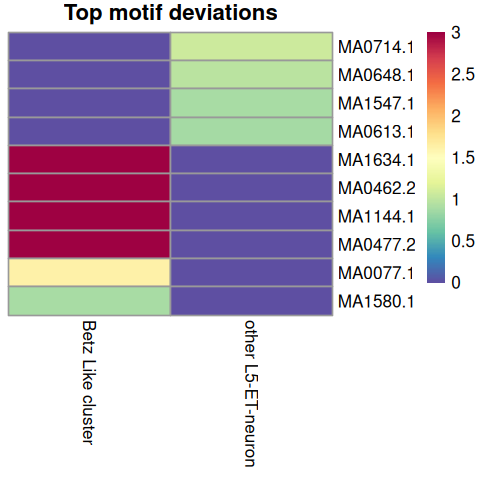

In [ ]:
options(repr.plot.width = 4, repr.plot.height = 4)

# 计算平均表达
avg_expr <- AverageExpression(obj_3, group.by = "ET_class", assays = "chromvar", features = top_motif$motif)

# AverageExpression返回的是一个list，提取chromvar矩阵
avg_expr_mat <- avg_expr[["chromvar"]]

# 每一行：
# 用每一行的每个值除以该行的最小值，然后取log
epsilon <- 1e-8
ratio_mat <- avg_expr_mat
for (i in 1:nrow(avg_expr_mat)) {
  row_vals <- avg_expr_mat[i, ]
  row_min <- min(row_vals)
  if (row_min == 0) {
    row_min <- epsilon
  }
  ratio_row <- log(row_vals / row_min)
  # 将大于14的设为14（展示时同色处理，适当拉长色带）
  ratio_row[ratio_row > 3] <- 3
  ratio_mat[i, ] <- ratio_row
}

# 设置更丰富的颜色梯度
my_palette <- colorRampPalette(rev(brewer.pal(50, "Spectral")))(200)

# 作热图，限制色阶在0到14，颜色梯度变化大一些
pheatmap(ratio_mat, 
         cluster_rows = F, 
         cluster_cols = F, 
         color = my_palette,
         main = "Top motif deviations",
         breaks = seq(0, 3, length.out = 201)
)

In [159]:
motif_list = c('MA0077.1','MA1580.1')
subset(markers_motif_1, motif %in% motif_list)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,motif
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
MA0077.1,4.259123e-15,2.340172,0.345,0.579,6.772006e-12,Betz Like cluster,MA0077.1
MA1580.1,1.805286e-05,1.284687,0.394,0.549,2.870404e-02,Betz Like cluster,MA1580.1


In [ ]:
saveRDS(obj_2, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_betz_snRNA/snATAC_addmotif.rds')

In [ ]:
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251223_MA0077.1_motif_plot.pdf",width = 7,height = 4)
MotifPlot(
  object = obj_2,
  # motifs = head(rownames(enriched.motifs))
  motifs = 'MA0077.1'
  # motifs = 'MA1580.1'
)
dev.off()


agg_record_1254481218 
                    2